In [1]:
from google.colab import drive
drive.mount('/content/drive')

import tensorflow as tf
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

!unzip -q -o "/content/drive/MyDrive/citrus_disease_dataset.zip" -d /content/citrus

# Unzipping the dataset from google drive which is more efficient

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import os
from pathlib import Path

print("MyDrive root:")
print(os.listdir('/content/drive/MyDrive'))

MyDrive root:
['Colab Notebooks', 'citrus_disease_dataset.zip', 'Classroom', 'Scanned_20220312-1822.pdf', 'Scanned_20220312-1826.pdf', 'Scanned_20220312-1828.pdf', 'El taliano', "I am sharing 'ijh' with you", "I am sharing 'dfg,m' with you", "I am sharing 'dghjbguj' with you", 'VID_34740709_091451_733.mp4', 'VID_31421216_082000_870.mp4', '20220522_210835.jpg', '20220522_210819.jpg', '20220522_210810.jpg', '20220522_210347.jpg', '20220522_210235.jpg', '20220522_210215.jpg', '20220522_210204.jpg', '20220516_225536.jpg', 'VID_29250521_065042_474.mp4', '20220421_165119.jpg', '20220421_165117.jpg', '20220421_165115.jpg', '20220421_165108.jpg', '20220421_165105.jpg', '20220421_165014.jpg', '20220421_165012.jpg', '20220421_165000.jpg', '20220421_164729.jpg', '20220421_164724.jpg', '20220421_164721.jpg', '20220421_164410.jpg', '20220421_164342.jpg', '20220522_210759.jpg', '20220522_210732.jpg', '20220522_210434.jpg', '20220522_210357.jpg', '20220421_164338.jpg', '20220421_164333.jpg', '2022042

Images per fine-grained class:
label
fruits_black spot     19
fruits_canker         78
fruits_greening       16
fruits_healthy        22
fruits_scab           15
leaves_black spot    171
leaves_canker        163
leaves_greening      204
leaves_healthy        58
leaves_melanose       13
Name: count, dtype: int64

Images per organ:
organ
leaves    609
fruits    150
Name: count, dtype: int64

Total images: 759
Total fine-grained classes (organ + disease): 10
Distinct disease names: 6


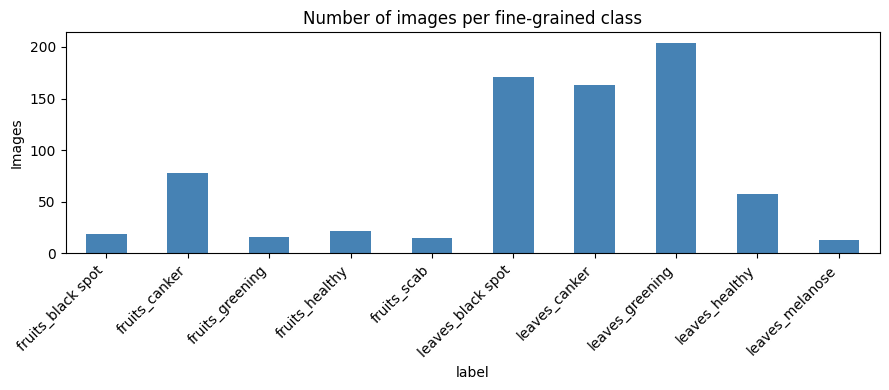

In [3]:
# Section 1 : Data Exploration
# Imports
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

#The path to the unzipped dataset
DATA_DIR = Path('/content/citrus')   # Updated to match the unzipped folder path
exts = {'.jpg', '.jpeg', '.png'}

# The image file types we want to count
rows = []
for p in DATA_DIR.rglob('*'):
    if p.suffix.lower() in exts:
        organ = p.parent.parent.name.lower()      # leaves / fruits
        disease = p.parent.name.lower()           # canker, black spot, ...
        rows.append({'path': str(p),
                     'organ': organ,
                     'disease': disease,
                     'label': f"{organ}_{disease}"})

# Converting the list of dictionaries into a table
df = pd.DataFrame(rows)

# Report the counts
print("Images per fine-grained class:")
print(df['label'].value_counts().sort_index())

print("\nImages per organ:")
print(df['organ'].value_counts())

print("\nTotal images:", len(df))
print("Total fine-grained classes (organ + disease):", df['label'].nunique())
print("Distinct disease names:", df['disease'].nunique())

# The visualization of the class distribution
counts = df['label'].value_counts().sort_index()
counts.plot(kind='bar', figsize=(9, 4), color='steelblue')
plt.title("Number of images per fine-grained class")
plt.ylabel("Images")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [4]:

# SECTION 2a: TRAIN / VALIDATION / TEST SPLIT

from sklearn.model_selection import train_test_split

# Fixed random seed: running the cell again gives the exact same split.
SEED = 42

# Split 1: 70% training, 30% held back
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df['label'],
    random_state=SEED
)

# Split 2: divide the held-back 30% in half
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df['label'],
    random_state=SEED
)

# Checking the results with the print statement
print("Train:", len(train_df), "| Validation:", len(val_df), "| Test:", len(test_df))

# Table of class counts per subset, to confirm every class appears in all three.
summary = pd.DataFrame({
    'train': train_df['label'].value_counts(),
    'val':   val_df['label'].value_counts(),
    'test':  test_df['label'].value_counts()
}).fillna(0).astype(int)
print(summary)

Train: 531 | Validation: 114 | Test: 114
                   train  val  test
label                              
fruits_black spot     13    3     3
fruits_canker         55   12    11
fruits_greening       11    3     2
fruits_healthy        15    3     4
fruits_scab           10    2     3
leaves_black spot    120   25    26
leaves_canker        114   25    24
leaves_greening      143   30    31
leaves_healthy        41    9     8
leaves_melanose        9    2     2


In [5]:
# SECTION 2b: RESIZING, NORMALISATION AND LABEL ENCODING
# Stage 1: fruit vs leaf at 128x128; Stage 2: disease at 256x256
import numpy as np
from PIL import Image

def load_images(frame, size):
    """Load every image in `frame`, force RGB, resize to size x size,
    and scale pixel values from 0-255 down to 0-1 (normalisation)."""
    imgs = [np.array(Image.open(p).convert('RGB').resize((size, size)))
            for p in frame['path']]
    return np.array(imgs, dtype='float32') / 255.0

# Stage 1: binary labels (0 = fruits, 1 = leaves), 128x128
S1_SIZE = 128
X1_train = load_images(train_df, S1_SIZE)
X1_val   = load_images(val_df,   S1_SIZE)
X1_test  = load_images(test_df,  S1_SIZE)
y1_train = (train_df['organ'] == 'leaves').astype(int).values
y1_val   = (val_df['organ']   == 'leaves').astype(int).values
y1_test  = (test_df['organ']  == 'leaves').astype(int).values

# Stage 2: disease labels, separately for each organ, 256x256
S2_SIZE = 256
stage2 = {}
for organ in ['fruits', 'leaves']:
    tr = train_df[train_df['organ'] == organ]
    va = val_df[val_df['organ'] == organ]
    te = test_df[test_df['organ'] == organ]
    classes = sorted(tr['disease'].unique())
    to_idx = {c: i for i, c in enumerate(classes)}
    stage2[organ] = {
        'classes': classes,
        'X_train': load_images(tr, S2_SIZE), 'y_train': tr['disease'].map(to_idx).values,
        'X_val':   load_images(va, S2_SIZE), 'y_val':   va['disease'].map(to_idx).values,
        'X_test':  load_images(te, S2_SIZE), 'y_test':  te['disease'].map(to_idx).values,
    }

# Check shapes and value range
print("Stage 1:", X1_train.shape, X1_val.shape, X1_test.shape)
print("Pixel range:", X1_train.min(), "to", X1_train.max())
for organ, d in stage2.items():
    print(organ, d['classes'], d['X_train'].shape, d['X_val'].shape, d['X_test'].shape)

Stage 1: (531, 128, 128, 3) (114, 128, 128, 3) (114, 128, 128, 3)
Pixel range: 0.0 to 1.0
fruits ['black spot', 'canker', 'greening', 'healthy', 'scab'] (104, 256, 256, 3) (23, 256, 256, 3) (23, 256, 256, 3)
leaves ['black spot', 'canker', 'greening', 'healthy', 'melanose'] (427, 256, 256, 3) (91, 256, 256, 3) (91, 256, 256, 3)


In [6]:
from tensorflow import keras
import numpy as np, os, pandas as pd
import matplotlib.pyplot as plt

model_s1    = keras.models.load_model("/content/drive/MyDrive/model_stage1.keras")
model_fruit = keras.models.load_model("/content/drive/MyDrive/model_stage2_fruit.keras")
model_leaf  = keras.models.load_model("/content/drive/MyDrive/model_stage2_leaf.keras")
stage2_models = {'fruits': model_fruit, 'leaves': model_leaf}

# Verification: should match the earlier validation results
print("Stage 1:", model_s1.evaluate(X1_val, y1_val, verbose=0))
print("Fruit:  ", model_fruit.evaluate(stage2['fruits']['X_val'], stage2['fruits']['y_val'], verbose=0))
print("Leaf:   ", model_leaf.evaluate(stage2['leaves']['X_val'], stage2['leaves']['y_val'], verbose=0))

Stage 1: [0.047806378453969955, 0.9649122953414917]
Fruit:   [1.0452373027801514, 0.5652173757553101]
Leaf:    [0.2722889184951782, 0.901098906993866]


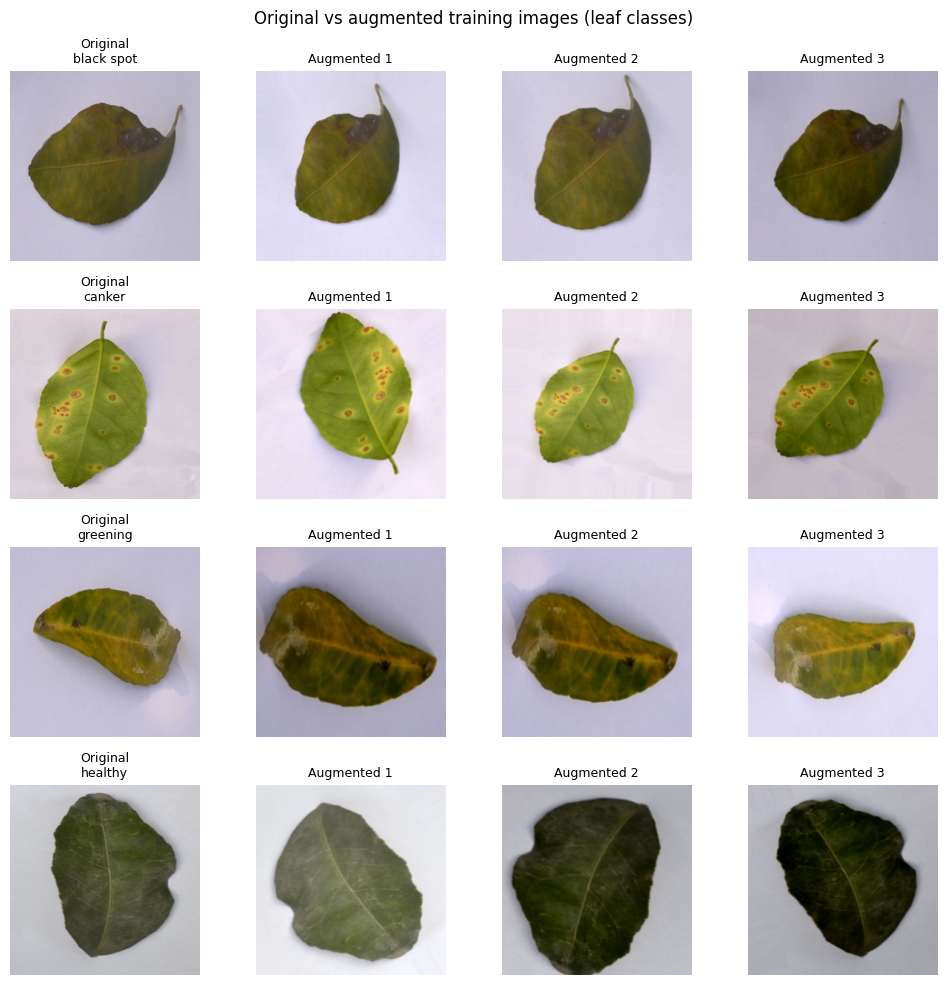

In [7]:
# SECTION 4: DATA AUGMENTATION

import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

#This makes the random augmentations repeatable
keras.utils.set_random_seed(SEED)

# Define the augmentation pipeline
augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1, fill_mode="nearest"),
    layers.RandomZoom(0.2, fill_mode="nearest"),
    layers.RandomBrightness(0.15, value_range=(0, 1)),
    layers.RandomContrast(0.2),
], name="augmentation")

#This picks one leaf training image from each of the 4 first classes
X = stage2['leaves']['X_train']
y = stage2['leaves']['y_train']
class_names = stage2['leaves']['classes']

fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for row in range(4):
    img = X[np.where(y == row)[0][0]]
    axes[row, 0].imshow(img)
    axes[row, 0].set_title(f"Original\n{class_names[row]}", fontsize=9)
    for col in range(1, 4):
        aug = augment(np.expand_dims(img, 0), training=True)[0]
        axes[row, col].imshow(aug.numpy().clip(0, 1))
        axes[row, col].set_title(f"Augmented {col}", fontsize=9)
for ax in axes.ravel():
    ax.axis('off')
plt.suptitle("Original vs augmented training images (leaf classes)")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/figuree2_augmentation.png", dpi=200, bbox_inches="tight")
plt.show()

In [8]:
# SECTION 5: CNN ARCHITECTURE
# Builds the Stage 1 (binary) and Stage 2 (multiclass) models
# and prints a summary of each

def make_augment():
    """Return a NEW augmentation pipeline each time it is called.
    A fresh copy is needed per model, because Keras locks a pipeline to the
    image size it is first used with (128x128 for Stage 1, 256x256 for Stage 2)."""
    return keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.1, fill_mode="nearest"),
        layers.RandomZoom(0.2, fill_mode="nearest"),
        layers.RandomBrightness(0.15, value_range=(0, 1)),
        layers.RandomContrast(0.2),
    ], name="augmentation")

def build_stage1(input_size=128):
    #Stage 1: binary fruit-vs-leaf CNN (6 conv, 3 max-pool, 3 dense)
    return keras.Sequential([
        layers.Input(shape=(input_size, input_size, 3)),   # 128x128 RGB input
        make_augment(),                                    # augmentation (only active during training)
        layers.Conv2D(32, 3, activation='relu'),           # 32 filters, 3x3 kernel, ReLU
        layers.Conv2D(32, 3, activation='relu'),
        layers.MaxPooling2D(2),                            # 2x2 pooling, halves height and width
        layers.Conv2D(64, 3, activation='relu'),
        layers.Conv2D(64, 3, activation='relu'),
        layers.MaxPooling2D(2),
        layers.Conv2D(128, 3, activation='relu'),
        layers.Conv2D(128, 3, activation='relu'),
        layers.MaxPooling2D(2),
        layers.Flatten(),                                  # 2D feature maps -> 1D vector
        layers.Dense(128, activation='relu'),              # fully connected, 128 neurons
        layers.Dense(128, activation='relu'),
        layers.Dense(1, activation='sigmoid'),             # 1 node: probability the image is a leaf
    ], name="stage1_fruit_vs_leaf")

def build_stage2(n_classes=5, input_size=256, name="stage2"):
    """Stage 2: disease CNN (4 conv, 4 max-pool, 2 dense), one model per organ."""
    return keras.Sequential([
        layers.Input(shape=(input_size, input_size, 3)),   # 256x256 RGB input
        make_augment(),                                    # its own fresh augmentation pipeline
        layers.Conv2D(16, 3, activation='relu'),
        layers.MaxPooling2D(2),
        layers.Conv2D(32, 3, activation='relu'),
        layers.MaxPooling2D(2),
        layers.Conv2D(64, 3, activation='relu'),
        layers.MaxPooling2D(2),
        layers.Conv2D(128, 3, activation='relu'),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(n_classes, activation='softmax'),
    ], name=name)

# Create the three models
model_s1    = build_stage1()
model_fruit = build_stage2(n_classes=5, name="stage2_fruit_diseases")
model_leaf  = build_stage2(n_classes=5, name="stage2_leaf_diseases")

# Print layer-by-layer summaries
model_s1.summary()
model_fruit.summary()
model_leaf.summary()

Model: "stage1_fruit_vs_leaf"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 124, 124, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 62, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 58, 58, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 29, 29, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 27, 27, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 25, 25, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     2,359,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,663,073 (10.16 MB)

 Trainable params: 2,663,073 (10.16 MB)

 Non-trainable params: 0 (0.00 B)

...

Model: "stage2_leaf_diseases"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 254, 254, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 127, 127, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 125, 125, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 62, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 60, 60, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,309,477 (12.62 MB)

 Trainable params: 3,309,477 (12.62 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# SECTION 6: MODEL COMPILATION
# Choose optimiser, loss and metric for each of the 3 models

# Stage 1: binary problem (fruit vs leaf), 1 sigmoid output node
model_s1.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Stage 2: multiclass problems (5 diseases each), 5 softmax output nodes
for m in [model_fruit, model_leaf]:
    m.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

print("All three models compiled.")

All three models compiled.


In [10]:
# SECTION 7: TRAINING (Stage 1 only for now)
# Train the fruit-vs-leaf model, record its History, save to Drive

import pickle

BATCH_SIZE = 16     # images per weight update
EPOCHS = 30         # maximum number of passes over the training set

def make_callbacks():
    #Early stopping: stop if validation loss hasn't improved for 8 epochs,
    #then roll back to the best epoch's weights.
    return [keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=8, restore_best_weights=True)]

def train(model, X_tr, y_tr, X_va, y_va, tag):
    #Train one model, save its history and weights, and return the history.
    keras.utils.set_random_seed(SEED)
    hist = model.fit(
        X_tr, y_tr,
        validation_data=(X_va, y_va),
        batch_size=BATCH_SIZE,
        epochs=EPOCHS,
        callbacks=make_callbacks(),
        verbose=2
    )
    # Save history  and the trained model to Drive
    with open(f"/content/drive/MyDrive/history_{tag}.pkl", "wb") as f:
        pickle.dump(hist.history, f)
    model.save(f"/content/drive/MyDrive/model_{tag}.keras")
    return hist

# Stage 1: fruit vs leaf
print("=== Training Stage 1: fruit vs leaf ===")
hist_s1 = train(model_s1, X1_train, y1_train, X1_val, y1_val, "stage1")

=== Training Stage 1: fruit vs leaf ===
Epoch 1/30
34/34 - 7s - 198ms/step - accuracy: 0.8437 - loss: 0.3566 - val_accuracy: 0.9561 - val_loss: 0.1953
Epoch 2/30
34/34 - 1s - 31ms/step - accuracy: 0.9171 - loss: 0.2816 - val_accuracy: 0.9386 - val_loss: 0.2355
Epoch 3/30
34/34 - 1s - 30ms/step - accuracy: 0.9416 - loss: 0.1964 - val_accuracy: 0.9737 - val_loss: 0.1223
Epoch 4/30
34/34 - 1s - 30ms/step - accuracy: 0.9416 - loss: 0.1786 - val_accuracy: 0.9474 - val_loss: 0.1735
Epoch 5/30
34/34 - 1s - 30ms/step - accuracy: 0.9510 - loss: 0.1424 - val_accuracy: 0.9737 - val_loss: 0.1022
Epoch 6/30
34/34 - 1s - 30ms/step - accuracy: 0.9661 - loss: 0.0830 - val_accuracy: 0.9649 - val_loss: 0.0638
Epoch 7/30
34/34 - 1s - 32ms/step - accuracy: 0.9699 - loss: 0.0779 - val_accuracy: 0.9649 - val_loss: 0.1935
Epoch 8/30
34/34 - 1s - 34ms/step - accuracy: 0.9699 - loss: 0.0937 - val_accuracy: 0.9825 - val_loss: 0.0602
Epoch 9/30
34/34 - 1s - 34ms/step - accuracy: 0.9755 - loss: 0.0658 - val_accur

In [11]:
# SECTION 7 continued: TRAINING, Stage 2 models
print("=== Training Stage 2: fruit diseases ===")
f = stage2['fruits']
hist_fruit = train(model_fruit, f['X_train'], f['y_train'],
                   f['X_val'], f['y_val'], "stage2_fruit")

print("\n=== Training Stage 2: leaf diseases ===")
l = stage2['leaves']
hist_leaf = train(model_leaf, l['X_train'], l['y_train'],
                  l['X_val'], l['y_val'], "stage2_leaf")

=== Training Stage 2: fruit diseases ===
Epoch 1/30
7/7 - 4s - 542ms/step - accuracy: 0.3558 - loss: 1.5413 - val_accuracy: 0.5217 - val_loss: 1.3422
Epoch 2/30
7/7 - 1s - 152ms/step - accuracy: 0.5288 - loss: 1.3951 - val_accuracy: 0.5217 - val_loss: 1.3949
Epoch 3/30
7/7 - 0s - 53ms/step - accuracy: 0.5288 - loss: 1.3705 - val_accuracy: 0.5217 - val_loss: 1.3320
Epoch 4/30
7/7 - 0s - 45ms/step - accuracy: 0.5288 - loss: 1.2797 - val_accuracy: 0.5217 - val_loss: 1.2962
Epoch 5/30
7/7 - 0s - 43ms/step - accuracy: 0.5385 - loss: 1.1823 - val_accuracy: 0.5652 - val_loss: 1.2878
Epoch 6/30
7/7 - 0s - 50ms/step - accuracy: 0.5481 - loss: 1.0675 - val_accuracy: 0.5217 - val_loss: 1.2251
Epoch 7/30
7/7 - 0s - 49ms/step - accuracy: 0.5962 - loss: 0.9919 - val_accuracy: 0.5652 - val_loss: 1.2105
Epoch 8/30
7/7 - 1s - 83ms/step - accuracy: 0.6346 - loss: 0.9238 - val_accuracy: 0.4783 - val_loss: 1.2236
Epoch 9/30
7/7 - 0s - 41ms/step - accuracy: 0.6635 - loss: 0.8636 - val_accuracy: 0.5217 - va

In [12]:
# Check which weights each model currently holds (compare with the training logs)
for name, m, X, y in [
    ("Stage 1",       model_s1,    X1_val,                  y1_val),
    ("Stage 2 fruit", model_fruit, stage2['fruits']['X_val'], stage2['fruits']['y_val']),
    ("Stage 2 leaf",  model_leaf,  stage2['leaves']['X_val'], stage2['leaves']['y_val']),
]:
    loss, acc = m.evaluate(X, y, verbose=0)
    print(f"{name}: val_loss = {loss:.4f}, val_accuracy = {acc:.4f}")

Stage 1: val_loss = 0.0549, val_accuracy = 0.9737
Stage 2 fruit: val_loss = 1.1089, val_accuracy = 0.6087
Stage 2 leaf: val_loss = 0.3311, val_accuracy = 0.8791


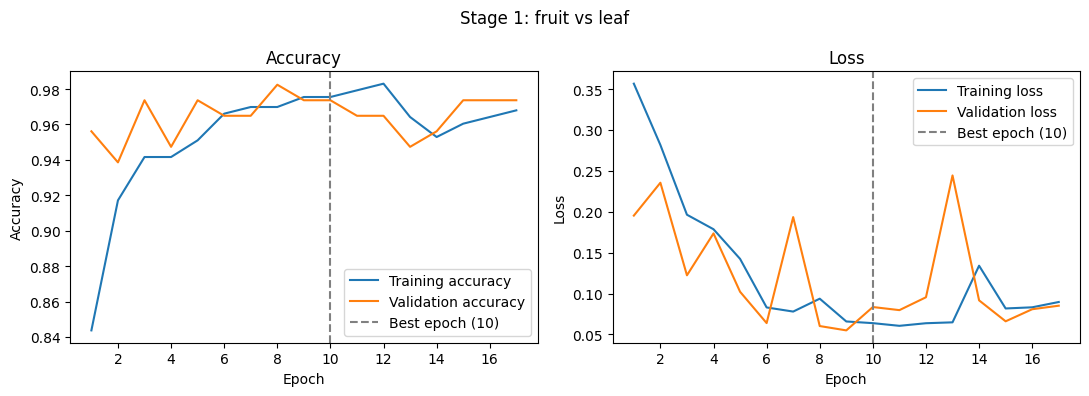

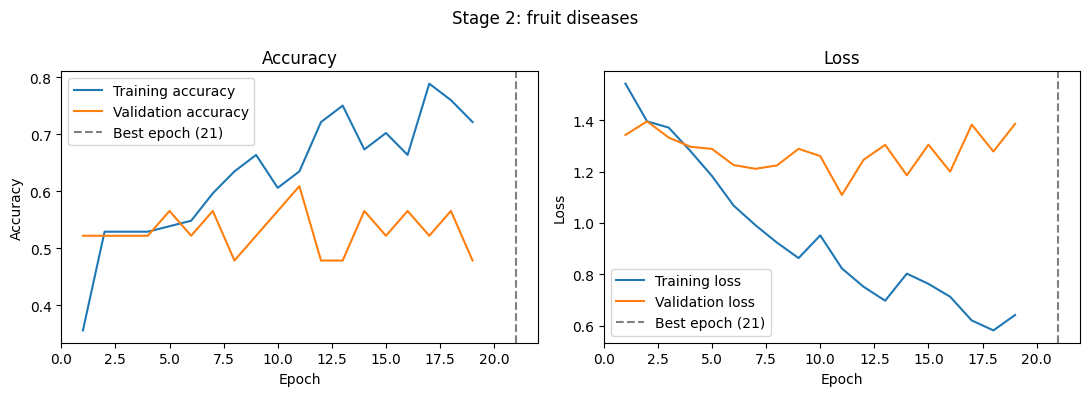

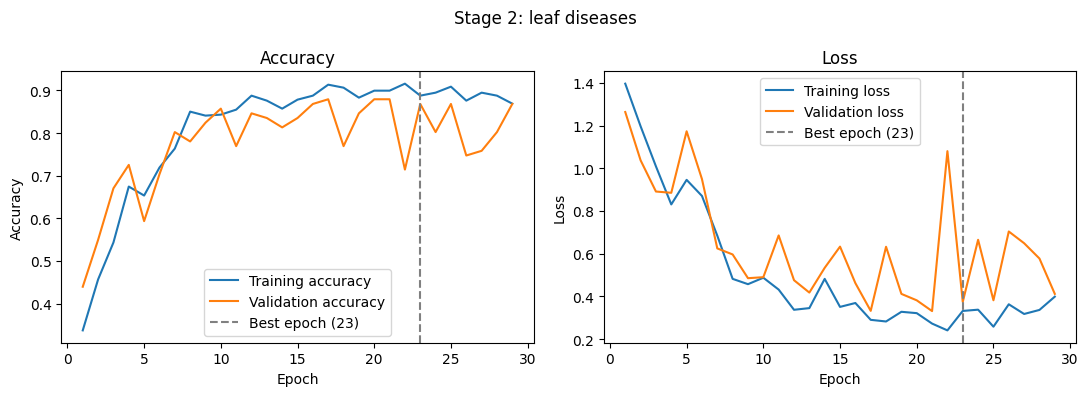

In [13]:

# SECTION 8: LEARNING CURVES
# Training vs validation accuracy and loss for each model

import matplotlib.pyplot as plt

def plot_curves(hist, title, filename, best_epoch):
    #Plot accuracy (left) and loss (right) for training vs validation.
    #best_epoch is the 1-based epoch whose weights were kept .
    h = hist.history
    epochs = range(1, len(h['loss']) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))

    ax[0].plot(epochs, h['accuracy'], label='Training accuracy')
    ax[0].plot(epochs, h['val_accuracy'], label='Validation accuracy')
    ax[0].set_title("Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Accuracy")

    ax[1].plot(epochs, h['loss'], label='Training loss')
    ax[1].plot(epochs, h['val_loss'], label='Validation loss')
    ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Loss")

    for a in ax:
        a.axvline(best_epoch, linestyle='--', color='grey', label=f'Best epoch ({best_epoch})')
        a.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(f"/content/drive/MyDrive/{filename}", dpi=200, bbox_inches="tight")
    plt.show()

plot_curves(hist_s1,    "Stage 1: fruit vs leaf",       "fig3_curves_stage1.png", 10)
plot_curves(hist_fruit, "Stage 2: fruit diseases",      "fig4_curves_fruit.png",  21)
plot_curves(hist_leaf,  "Stage 2: leaf diseases",       "fig5_curves_leaf.png",   23)

In [14]:
# SECTION 9: CLASSIFICATION PERFORMANCE ON THE TEST SET
# Accuracy, precision, recall and F1 for each of the 3 models

from sklearn.metrics import classification_report, accuracy_score

# Stage 1: binary (0 = fruit, 1 = leaf)
p1 = (model_s1.predict(X1_test, verbose=0).ravel() > 0.5).astype(int)
print("Stage 1: fruit vs leaf (test set) ")
print("Accuracy:", round(accuracy_score(y1_test, p1), 4))
print(classification_report(y1_test, p1, target_names=['fruit', 'leaf'], digits=3, zero_division=0))

# Stage 2: fruit and leaf disease models
stage2_models = {'fruits': model_fruit, 'leaves': model_leaf}
preds2 = {}
for organ, m in stage2_models.items():
    d = stage2[organ]
    probs = m.predict(d['X_test'], verbose=0)
    preds2[organ] = probs.argmax(axis=1)
    print("Accuracy:", round(accuracy_score(d['y_test'], preds2[organ]), 4))
    print(classification_report(d['y_test'], preds2[organ],
                                labels=range(5), target_names=d['classes'],
                                digits=3, zero_division=0))

Stage 1: fruit vs leaf (test set) 
Accuracy: 0.9825
              precision    recall  f1-score   support

       fruit      0.957     0.957     0.957        23
        leaf      0.989     0.989     0.989        91

    accuracy                          0.982       114
   macro avg      0.973     0.973     0.973       114
weighted avg      0.982     0.982     0.982       114

Accuracy: 0.6087
              precision    recall  f1-score   support

  black spot      0.000     0.000     0.000         3
      canker      0.667     0.909     0.769        11
    greening      0.333     0.500     0.400         2
     healthy      0.500     0.250     0.333         4
        scab      0.667     0.667     0.667         3

    accuracy                          0.609        23
   macro avg      0.433     0.465     0.434        23
weighted avg      0.522     0.609     0.548        23



Accuracy: 0.9121
              precision    recall  f1-score   support

  black spot      0.952     0.769     0.851        26
      canker      1.000     0.917     0.957        24
    greening      0.838     1.000     0.912        31
     healthy      1.000     1.000     1.000         8
    melanose      0.667     1.000     0.800         2

    accuracy                          0.912        91
   macro avg      0.891     0.937     0.904        91
weighted avg      0.924     0.912     0.912        91



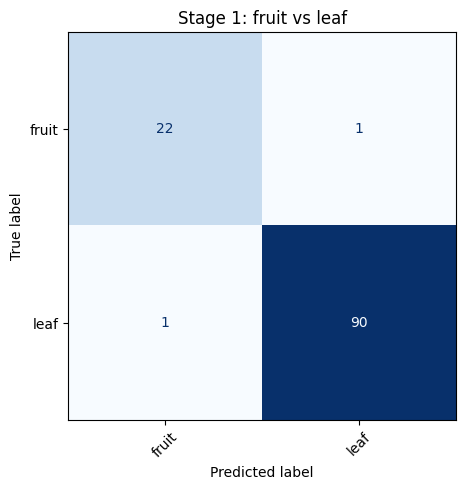

Stage 1: fruit vs leaf
[[22  1]
 [ 1 90]]



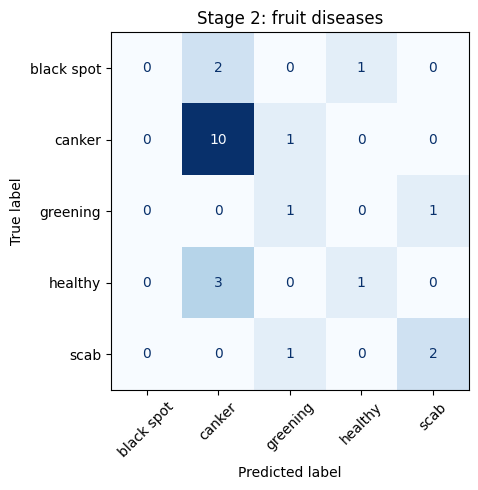

Stage 2: fruit diseases
[[ 0  2  0  1  0]
 [ 0 10  1  0  0]
 [ 0  0  1  0  1]
 [ 0  3  0  1  0]
 [ 0  0  1  0  2]]



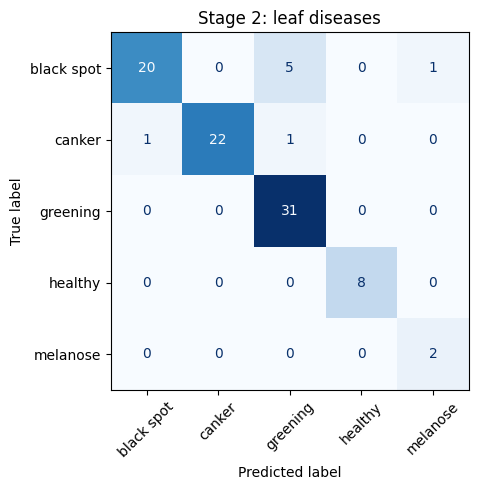

Stage 2: leaf diseases
[[20  0  5  0  1]
 [ 1 22  1  0  0]
 [ 0  0 31  0  0]
 [ 0  0  0  8  0]
 [ 0  0  0  0  2]]



In [15]:
# SECTION 10: CONFUSION MATRICES (test set)
# Rows = true class, columns = predicted class

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def plot_cm(y_true, y_pred, labels, title, filename):
    #Draw a confusion matrix, save it to Drive, and print the raw counts.

    cm = confusion_matrix(y_true, y_pred, labels=range(len(labels)))
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(
        ax=ax, cmap='Blues', colorbar=False, xticks_rotation=45)
    ax.set_title(title)
    plt.tight_layout()
    plt.savefig(f"/content/drive/MyDrive/{filename}", dpi=200, bbox_inches="tight")
    plt.show()
    print(title); print(cm); print()

plot_cm(y1_test, p1, ['fruit', 'leaf'],
        "Stage 1: fruit vs leaf", "fig6_cm_stage1.png")
plot_cm(stage2['fruits']['y_test'], preds2['fruits'], stage2['fruits']['classes'],
        "Stage 2: fruit diseases", "fig7_cm_fruit.png")
plot_cm(stage2['leaves']['y_test'], preds2['leaves'], stage2['leaves']['classes'],
        "Stage 2: leaf diseases", "fig8_cm_leaf.png")

Total Stage 2 errors: 17
 organ  idx       true  predicted  confidence                file
fruits   21    healthy     canker       0.776    Healthy (12).jpg
fruits   14    healthy     canker       0.770     Healthy (7).jpg
fruits    0 black spot     canker       0.741 Black spot (19).jpg
fruits   19 black spot     canker       0.710 Black spot (16).jpg
fruits   15     canker   greening       0.652    Canker (103).jpg
fruits   13 black spot    healthy       0.643 Black spot (17).jpg
fruits    3    healthy     canker       0.605     Healthy (5).jpg
fruits   11   greening       scab       0.412   Greening (11).jpg
fruits    7       scab   greening       0.355         17Catla.jpg
leaves   65 black spot   greening       0.873          b (47).png
leaves   74 black spot   melanose       0.837              74.jpg
leaves   72 black spot   greening       0.834         b (134).png
leaves   11     canker black spot       0.817           108.p.png
leaves   28     canker   greening       0.588      

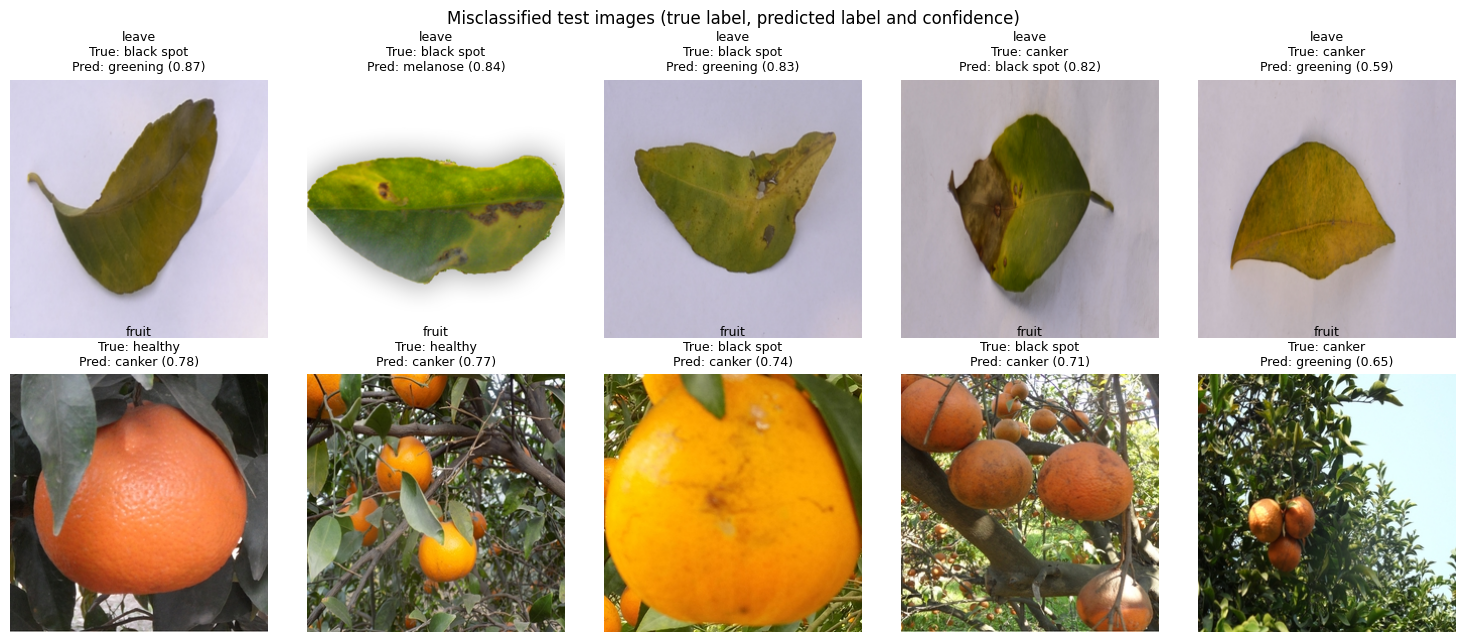

In [16]:

# SECTION 11: ERROR ANALYSIS
# Show misclassified test images with true label, prediction
# and the model's confidence in its (wrong) answer

rows = []   # one row per misclassified image
for organ in ['leaves', 'fruits']:
    te = test_df[test_df['organ'] == organ].reset_index(drop=True)   # same order as X_test
    d = stage2[organ]
    probs = stage2_models[organ].predict(d['X_test'], verbose=0)
    pred = probs.argmax(axis=1)
    for i in np.where(pred != d['y_test'])[0]:                       # indices of wrong predictions
        rows.append({
            'organ': organ,
            'idx': i,                                                # position in X_test
            'true': d['classes'][d['y_test'][i]],
            'predicted': d['classes'][pred[i]],
            'confidence': round(float(probs[i].max()), 3),           # probability given to the wrong class
            'file': os.path.basename(te.loc[i, 'path']),
        })

err = pd.DataFrame(rows)
print("Total Stage 2 errors:", len(err))
print(err.sort_values(['organ', 'confidence'], ascending=[True, False]).to_string(index=False))

# Plot the 5 most confidently wrong images per organ
fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
for r, organ in enumerate(['leaves', 'fruits']):
    top = err[err['organ'] == organ].sort_values('confidence', ascending=False).head(5)
    for c, (_, row) in enumerate(top.iterrows()):
        axes[r, c].imshow(stage2[organ]['X_test'][row['idx']])
        axes[r, c].set_title(f"{organ[:-1]}\nTrue: {row['true']}\nPred: {row['predicted']} ({row['confidence']:.2f})",
                             fontsize=9)
for ax in axes.ravel():
    ax.axis('off')
plt.suptitle("Misclassified test images (true label, predicted label and confidence)")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/figg9_errors.png", dpi=200, bbox_inches="tight")
plt.show()